In [ ]:
from pathlib import Path
import sys
import pandas as pd

current = Path.cwd()

while current != current.parent:
    if (
        (current / "src").is_dir()
        and (current / "data").is_dir()
    ):
        PROJECT_ROOT = current
        break

    current = current.parent

print("PROJECT_ROOT =", PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.preprocessing import (
    find_image,
    preprocess_image
)

print("Preprocessing functions imported")

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "HAM10000"

METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

IMAGE_DIRS = [
    DATA_DIR / "HAM10000_images_part_1",
    DATA_DIR / "HAM10000_images_part_2"
]

print()
print("DATA_DIR:", DATA_DIR)
print("Metadata exists:", METADATA_PATH.exists())
print("Image folder 1 exists:", IMAGE_DIRS[0].exists())
print("Image folder 2 exists:", IMAGE_DIRS[1].exists())


df = pd.read_csv(METADATA_PATH)

print()
print("Dataset shape:", df.shape)

image_id = df.iloc[0]["image_id"]

image_path = find_image(
    image_id,
    IMAGE_DIRS
)

print()
print("Image ID:", image_id)
print("Image path:", image_path)
print("Image exists:", image_path.exists() if image_path else False)

PROJECT_ROOT = d:\College\THAPAR\SEM 5\Software Engineering\Project\SOFTWARE-ENGINEERING
Preprocessing functions imported

DATA_DIR: d:\College\THAPAR\SEM 5\Software Engineering\Project\SOFTWARE-ENGINEERING\data\raw\HAM10000
Metadata exists: True
Image folder 1 exists: True
Image folder 2 exists: True

Dataset shape: (10015, 7)

Image ID: ISIC_0027419
Image path: d:\College\THAPAR\SEM 5\Software Engineering\Project\SOFTWARE-ENGINEERING\data\raw\HAM10000\HAM10000_images_part_1\ISIC_0027419.jpg
Image exists: True


In [3]:
processed_image = preprocess_image(image_path)

print("Shape:", processed_image.shape)
print("Data type:", processed_image.dtype)
print("Minimum pixel value:", processed_image.min())
print("Maximum pixel value:", processed_image.max())

Shape: (224, 224, 3)
Data type: float32
Minimum pixel value: 0.1882353
Maximum pixel value: 1.0


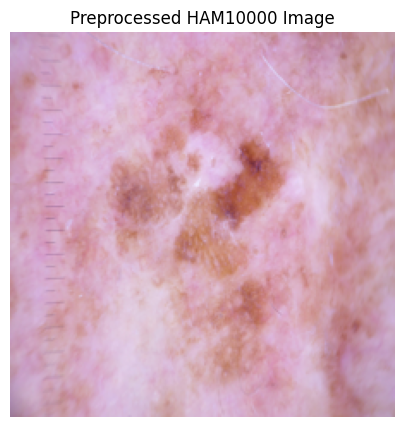

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(processed_image)
plt.axis("off")
plt.title("Preprocessed HAM10000 Image")
plt.show()

In [5]:
missing_images = []

for image_id in df["image_id"]:

    image_path = find_image(
        image_id,
        IMAGE_DIRS
    )

    if image_path is None:
        missing_images.append(image_id)

print("Total images in metadata:", len(df))
print("Missing images:", len(missing_images))

Total images in metadata: 10015
Missing images: 0


In [6]:
from PIL import Image

corrupted_images = []

for image_id in df["image_id"]:

    image_path = find_image(
        image_id,
        IMAGE_DIRS
    )

    if image_path is None:
        continue

    try:
        with Image.open(image_path) as image:
            image.verify()

    except Exception as e:
        corrupted_images.append({
            "image_id": image_id,
            "error": str(e)
        })

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [7]:
from src.data.splitter import stratified_split

In [15]:
train_df, val_df, test_df = stratified_split(
    df,
    target_column="dx"
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (7010, 7)
Validation: (1502, 7)
Test: (1503, 7)


In [16]:
print("Original distribution:")
print(df["dx"].value_counts(normalize=True))

print("\nTrain distribution:")
print(train_df["dx"].value_counts(normalize=True))

print("\nValidation distribution:")
print(val_df["dx"].value_counts(normalize=True))

print("\nTest distribution:")
print(test_df["dx"].value_counts(normalize=True))

Original distribution:
dx
nv       0.669496
mel      0.111133
bkl      0.109735
bcc      0.051323
akiec    0.032651
vasc     0.014179
df       0.011483
Name: proportion, dtype: float64

Train distribution:
dx
nv       0.669472
mel      0.111127
bkl      0.109700
bcc      0.051355
akiec    0.032668
vasc     0.014123
df       0.011555
Name: proportion, dtype: float64

Validation distribution:
dx
nv       0.669774
mel      0.111185
bkl      0.109854
bcc      0.051265
akiec    0.032623
vasc     0.013981
df       0.011318
Name: proportion, dtype: float64

Test distribution:
dx
nv       0.669328
mel      0.111111
bkl      0.109780
bcc      0.051231
akiec    0.032601
vasc     0.014637
df       0.011311
Name: proportion, dtype: float64


In [10]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [11]:
train_df.to_csv(
    PROCESSED_DIR / "train_metadata.csv",
    index=False
)

val_df.to_csv(
    PROCESSED_DIR / "val_metadata.csv",
    index=False
)

test_df.to_csv(
    PROCESSED_DIR / "test_metadata.csv",
    index=False
)

In [17]:
print((PROCESSED_DIR / "train_metadata.csv").exists())
print((PROCESSED_DIR / "val_metadata.csv").exists())
print((PROCESSED_DIR / "test_metadata.csv").exists())

True
True
True


In [18]:
from src.data.database_loader import load_data
test_sample = train_df.head(10)

In [19]:
images, labels = load_data(
    test_sample,
    IMAGE_DIRS
)

In [20]:
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Pixel minimum:", images.min())
print("Pixel maximum:", images.max())

Images shape: (10, 224, 224, 3)
Labels shape: (10,)
Image dtype: float32
Pixel minimum: 0.003921569
Pixel maximum: 1.0
